# Activity 4.1.4 Comparing optimisers

## Objective
Build a neural network model that predicts survivors of the Titanic voyage using data from the Titanic data set. Create and train the model with Adam and then RMSProp, and evaluate it to see which optimiser was most effective.

## Assessment criteria
By completing this activity, you'll be able to provide evidence that you can:
- load a data set for training a neural network model
- perform relevant preprocessing steps and split the data
- define a function to create and train a neural network model
- interpret model output and explain your conclusions
- select the appropriate model and justify your choice.

## Activity guidance
1. Import the relevant libraries and load the Titanic data set.
2. Complete data pre-processing, including dropping irrelevant columns and converting categorical data to binary values.
3. Fill in any missing values in the remaining columns.
4. Define features and a target variable.
5. Split the data into training and test sets.
5. Standardise features.
7. Define a function to create and train a neural network with:
  - One input layer of a number of neurons equal to the number of input features
  - One hidden layer
  - ReLU activations in every layer except the output layer, where you will use Sigmoid
  - Binary cross entropy as loss
  - Optimiser as the parameter of the function
8. Create and train models with Adam.
9. Create and train models with RMSProp.
10. Evaluate the models.


## Recording your method
As you prepare the data and build your models, make notes about the decisions you make. You may wish to record these comments in your Notebook, either beside the code, or in your reflection space at the end.

> Start your activity here. Select the pen from the toolbar to add your entry.

# **1. Import the relevant libraries and load the Titanic data set.**

In [1]:
# Import the relevant libraries.
import numpy as np
import pandas as pd
from sklearn.model_selection import train_test_split
from sklearn.preprocessing import StandardScaler
from keras.models import Sequential
from keras.layers import Dense
from keras.optimizers import Adam, RMSprop
import matplotlib.pyplot as plt

In [2]:
# Load the Titanic data set.
url = "https://raw.githubusercontent.com/datasciencedojo/datasets/master/titanic.csv"
titanic_df = pd.read_csv(url)

In [3]:
titanic_df.head()

,PassengerId,Survived,Pclass,Name,Sex,Age,SibSp,Parch,Ticket,Fare,Cabin,Embarked
0,1,0,3,"Braund, Mr. Owen Harris",male,22.0,1,0,A/5 21171,7.2500,NaN,S
1,2,1,1,"Cumings, Mrs. John Bradley (Florence Briggs Th...",female,38.0,1,0,PC 17599,71.2833,C85,C
2,3,1,3,"Heikkinen, Miss. Laina",female,26.0,0,0,STON/O2. 3101282,7.9250,NaN,S
3,4,1,1,"Futrelle, Mrs. Jacques Heath (Lily May Peel)",female,35.0,1,0,113803,53.1000,C123,S
4,5,0,3,"Allen, Mr. William Henry",male,35.0,0,0,373450,8.0500,NaN,S


In [4]:
titanic_df.describe()

,PassengerId,Survived,Pclass,Age,SibSp,Parch,Fare
count,891.000000,891.000000,891.000000,714.000000,891.000000,891.000000,891.000000
mean,446.000000,0.383838,2.308642,29.699118,0.523008,0.381594,32.204208
std,257.353842,0.486592,0.836071,14.526497,1.102743,0.806057,49.693429
min,1.000000,0.000000,1.000000,0.420000,0.000000,0.000000,0.000000
25%,223.500000,0.000000,2.000000,20.125000,0.000000,0.000000,7.910400
50%,446.000000,0.000000,3.000000,28.000000,0.000000,0.000000,14.454200
75%,668.500000,1.000000,3.000000,38.000000,1.000000,0.000000,31.000000
max,891.000000,1.000000,3.000000,80.000000,8.000000,6.000000,512.329200


In [5]:
titanic_df.info()

<class 'pandas.core.frame.DataFrame'>
RangeIndex: 891 entries, 0 to 890
Data columns (total 12 columns):
 #   Column       Non-Null Count  Dtype  
---  ------       --------------  -----  
 0   PassengerId  891 non-null    int64  
 1   Survived     891 non-null    int64  
 2   Pclass       891 non-null    int64  
 3   Name         891 non-null    object 
 4   Sex          891 non-null    object 
 5   Age          714 non-null    float64
 6   SibSp        891 non-null    int64  
 7   Parch        891 non-null    int64  
 8   Ticket       891 non-null    object 
 9   Fare         891 non-null    float64
 10  Cabin        204 non-null    object 
 11  Embarked     889 non-null    object 
dtypes: float64(2), int64(5), object(5)
memory usage: 83.7+ KB


# **2. Complete data pre-processing, including dropping irrelevant columns and converting categorical data to binary values.**

In [6]:
# Drop irrelevant features
# titanic_df = titanic_df.drop(['Name', 'Ticket', 'Cabin', 'PassengerId'], axis=1)
titanic_df = titanic_df.drop(['Name', 'Ticket', 'Cabin', 'PassengerId'], axis=1, errors='ignore')

In [7]:
# Converting categorical data to binary values
titanic_df['Sex'] = titanic_df['Sex'].map({'male': 0, 'female': 1})
titanic_df['Embarked'] = titanic_df['Embarked'].map({'S': 0, 'C':1, 'Q': 2})

In [8]:
titanic_df.isnull().sum()

,0
Survived,0
Pclass,0
Sex,0
Age,177
SibSp,0
Parch,0
Fare,0
Embarked,2


# **3. Fill in any missing values in the remaining columns.**

In [14]:
titanic_df['Embarked'].value_counts()

,count
Embarked,
0.0,646
1.0,168
2.0,77


In [15]:
# Fill missing values
titanic_df['Age'].fillna(titanic_df['Age'].median(), inplace=True)
titanic_df['Embarked'].fillna(0, inplace=True)

/tmp/ipykernel_5594/50507888.py:2: FutureWarning: A value is trying to be set on a copy of a DataFrame or Series through chained assignment using an inplace method.
The behavior will change in pandas 3.0. This inplace method will never work because the intermediate object on which we are setting values always behaves as a copy.

For example, when doing 'df[col].method(value, inplace=True)', try using 'df.method({col: value}, inplace=True)' or df[col] = df[col].method(value) instead, to perform the operation inplace on the original object.


  titanic_df['Age'].fillna(titanic_df['Age'].median(), inplace=True)
/tmp/ipykernel_5594/50507888.py:3: FutureWarning: A value is trying to be set on a copy of a DataFrame or Series through chained assignment using an inplace method.
The behavior will change in pandas 3.0. This inplace method will never work because the intermediate object on which we are setting values always behaves as a copy.

For example, when doing 'df[col].method(value, inplac

In [16]:
titanic_df['Age'] = titanic_df['Age'].fillna(titanic_df['Age'].median())
titanic_df['Embarked'] = titanic_df['Embarked'].fillna(0)

In [17]:
# evaluate missing values fix
titanic_df.isnull().sum()

,0
Survived,0
Pclass,0
Sex,0
Age,0
SibSp,0
Parch,0
Fare,0
Embarked,0


In [18]:
titanic_df['Sex'].value_counts()

,count
Sex,
0,577
1,314


# **4. Define features and a target variable.**

In [19]:
# Define features and target varible
X = titanic_df.drop('Survived', axis=1)
y = titanic_df['Survived']

# **5. Split the data into training and test sets.**

In [20]:
# Split the data into training and test sets
X_train, X_test, y_train, y_test = train_test_split(X, y, test_size=0.2, random_state=42)

# **6. Standardise features.**

In [21]:
# Standarized the features
scaler = StandardScaler()
X_train = scaler.fit_transform(X_train)
X_test = scaler.transform(X_test)

# **7. Define a function to create and train a neural network with:**
- One input layer of a number of neurons equal to the number of input features
- One hidden layer
- ReLU activations in every layer except the output layer, where you will use Sigmoid
- Binary cross entropy as loss
- Optimiser as the parameter of the function

In [22]:
# number of features to check
X_train.shape[1]

7

In [23]:
# Import Tensorflow
import tensorflow as tf

# One input layer of a number of neurons equal to the number of input features
model = tf.keras.Sequential([tf.keras.layers.Dense(32, activation='relu', input_shape=(X_train.shape[1],)),
                             tf.keras.layers.Dense(16, activation='relu'),
                             tf.keras.layers.Dense(1, activation='sigmoid')])


/usr/local/lib/python3.12/dist-packages/keras/src/layers/core/dense.py:106: UserWarning: Do not pass an `input_shape`/`input_dim` argument to a layer. When using Sequential models, prefer using an `Input(shape)` object as the first layer in the model instead.
  super().__init__(activity_regularizer=activity_regularizer, **kwargs)


In [24]:
# Binary cross entropy as loss
def build_model(optimizer):
  model = tf.keras.Sequential([tf.keras.layers.Dense(32, activation='relu', input_shape=(X_train.shape[1],)),
                             tf.keras.layers.Dense(16, activation='relu'),
                             tf.keras.layers.Dense(1, activation='sigmoid')])
  model.compile(optimizer=optimizer, loss='binary_crossentropy', metrics=['accuracy'])

  return model

# **8. Create and train models with Adam.**

In [25]:
# Create and train models with Adam
adam_model = build_model(Adam(learning_rate=0.001))
adam_model.fit(X_train, y_train, epochs=100, batch_size=32)


Epoch 1/100
23/23 ━━━━━━━━━━━━━━━━━━━━ 1s 3ms/step - accuracy: 0.6784 - loss: 0.6502
Epoch 2/100
23/23 ━━━━━━━━━━━━━━━━━━━━ 0s 3ms/step - accuracy: 0.7444 - loss: 0.5821 
Epoch 3/100
23/23 ━━━━━━━━━━━━━━━━━━━━ 0s 3ms/step - accuracy: 0.8048 - loss: 0.5328 
Epoch 4/100
23/23 ━━━━━━━━━━━━━━━━━━━━ 0s 3ms/step - accuracy: 0.8076 - loss: 0.4932 
Epoch 5/100
23/23 ━━━━━━━━━━━━━━━━━━━━ 0s 3ms/step - accuracy: 0.8188 - loss: 0.4662 
Epoch 6/100
23/23 ━━━━━━━━━━━━━━━━━━━━ 0s 3ms/step - accuracy: 0.8160 - loss: 0.4495 
Epoch 7/100
23/23 ━━━━━━━━━━━━━━━━━━━━ 0s 3ms/step - accuracy: 0.8160 - loss: 0.4393 
Epoch 8/100
23/23 ━━━━━━━━━━━━━━━━━━━━ 0s 3ms/step - accuracy: 0.8188 - loss: 0.4316 
Epoch 9/100
23/23 ━━━━━━━━━━━━━━━━━━━━ 0s 3ms/step - accuracy: 0.8188 - loss: 0.4273 
Epoch 10/100
23/23 ━━━━━━━━━━━━━━━━━━━━ 0s 3ms/step - accuracy: 0.8230 - loss: 0.4233 
Epoch 11/100
23/23 ━━━━━━━━━━━━━━━━━━━━ 0s 3ms/step - accuracy: 0.8132 - loss: 0.4207 
Epoch 12/100
23/23 ━━━━━━━━━━━━━━━━━━━━ 0s 3ms/step -

# **9. Create and train models with RMSProp.**

In [26]:
from keras.src.optimizers import rmsprop

# Create and train models with RMSProp
rmsprop_model = build_model(RMSprop(learning_rate=0.001))
rmsprop_model.fit(X_train, y_train, epochs=100, batch_size=32)


Epoch 1/100


/usr/local/lib/python3.12/dist-packages/keras/src/layers/core/dense.py:106: UserWarning: Do not pass an `input_shape`/`input_dim` argument to a layer. When using Sequential models, prefer using an `Input(shape)` object as the first layer in the model instead.
  super().__init__(activity_regularizer=activity_regularizer, **kwargs)


23/23 ━━━━━━━━━━━━━━━━━━━━ 1s 3ms/step - accuracy: 0.5744 - loss: 0.6670   
Epoch 2/100
23/23 ━━━━━━━━━━━━━━━━━━━━ 0s 3ms/step - accuracy: 0.7346 - loss: 0.5790 
Epoch 3/100
23/23 ━━━━━━━━━━━━━━━━━━━━ 0s 3ms/step - accuracy: 0.7823 - loss: 0.5219 
Epoch 4/100
23/23 ━━━━━━━━━━━━━━━━━━━━ 0s 3ms/step - accuracy: 0.8006 - loss: 0.4832 
Epoch 5/100
23/23 ━━━━━━━━━━━━━━━━━━━━ 0s 4ms/step - accuracy: 0.8076 - loss: 0.4580
Epoch 6/100
23/23 ━━━━━━━━━━━━━━━━━━━━ 0s 3ms/step - accuracy: 0.8146 - loss: 0.4437 
Epoch 7/100
23/23 ━━━━━━━━━━━━━━━━━━━━ 0s 3ms/step - accuracy: 0.8132 - loss: 0.4349 
Epoch 8/100
23/23 ━━━━━━━━━━━━━━━━━━━━ 0s 3ms/step - accuracy: 0.8174 - loss: 0.4286 
Epoch 9/100
23/23 ━━━━━━━━━━━━━━━━━━━━ 0s 3ms/step - accuracy: 0.8202 - loss: 0.4239 
Epoch 10/100
23/23 ━━━━━━━━━━━━━━━━━━━━ 0s 3ms/step - accuracy: 0.8230 - loss: 0.4199 
Epoch 11/100
23/23 ━━━━━━━━━━━━━━━━━━━━ 0s 3ms/step - accuracy: 0.8244 - loss: 0.4172 
Epoch 12/100
23/23 ━━━━━━━━━━━━━━━━━━━━ 0s 3ms/step - accuracy:

# **10. Evaluate the models.**

In [27]:
# Evaluate the models
adam_loss, adam_accuracy = adam_model.evaluate(X_test, y_test)
rmsp_loss, rmsp_accuracy = rmsprop_model.evaluate(X_test, y_test)

print("Adam Model - Loss: {:.4f}, Accuracy: {:.4f}".format(adam_loss, adam_accuracy))
print("RMSProp Model - Loss: {:.4f}, Accuracy: {:.4f}".format(rmsp_loss, rmsp_accuracy))

6/6 ━━━━━━━━━━━━━━━━━━━━ 0s 6ms/step - accuracy: 0.8268 - loss: 0.4497  
6/6 ━━━━━━━━━━━━━━━━━━━━ 0s 8ms/step - accuracy: 0.8101 - loss: 0.4410  
Adam Model - Loss: 0.4497, Accuracy: 0.8268
RMSProp Model - Loss: 0.4410, Accuracy: 0.8101


# Reflect

Summarise the decisions you made when preparing the data and building the models.

Interpret the model output, and state your conclusions comparing the performance of Adam and RMSProp.

What makes this experiment a valid comparison of the two optimisers? Explain why the observed effects can be attributed to the optimisers. If you perform the experiment repeatedly, what kind of variation would you expect in your results?

Write a brief paragraph highlighting your process and the rationale to showcase critical thinking and problem-solving.

The model outcome is good considering the network used just one layer of neurons. Adam resulted in 81% accuracy and 0.45 loss whereas RMSProp resulted in 81% and 0.44 loss. Both models predicted 81% survivals which is a solid and very close results considering the simple neural network.

# Activity 4.2.4 Implementing regularisation techniques

## Objective
Using the neural network model you built above, modify the ‘create_model’ function to include dropout and L2 regularisation.

## Assessment criteria
By completing this activity, you will be able to provide evidence that you can:
- define a function to create and train a neural network model
- interpret model output and explain your conclusions
- select the appropriate model and justify your choice.

## Activity steps
1. Import the L2 regulariser and dropout.
3. Run a model function with dropout and regularisation included.
4. Create and train a model with Adam optimisation, l2 regularisation and dropout.
5. Create and train a model with RMSProp optimisation, l2 regularisation and dropout.
6. Plot model accuracy and loss.
7. Evaluate the models.


# **1. Import the L2 regulariser and dropout.**

In [ ]:
# Import the regulariser and dropout.
from keras.regularizers import l2
from keras.layers import Dense, Dropout

# **2. Run a model function with dropout and regularisation included.**

In [ ]:
# Function regularization and dropout
def build_model(optimizer):
  model = tf.keras.Sequential([tf.keras.layers.Dense(32, activation='relu', input_shape=(X_train.shape[1],), kernel_regularizer=l2(0.001)),
                               Dropout(0.3),
                             tf.keras.layers.Dense(16, activation='relu', kernel_regularizer=l2(0.001)),
                               Dropout(0.3),
                             tf.keras.layers.Dense(1, activation='sigmoid')])
  model.compile(optimizer=optimizer, loss='binary_crossentropy', metrics=['accuracy'])
  return model

# **3. Create and train a model with Adam optimisation, l2 regularisation and dropout.**

In [ ]:
# Adam optimization and L2 regularisation
adam_model = build_model(Adam(learning_rate=0.001))
adam_model.fit(X_train, y_train, epochs=100, batch_size=32)

Epoch 1/100
23/23 ━━━━━━━━━━━━━━━━━━━━ 2s 5ms/step - accuracy: 0.5951 - loss: 0.7260
Epoch 2/100
23/23 ━━━━━━━━━━━━━━━━━━━━ 0s 4ms/step - accuracy: 0.6307 - loss: 0.6793
Epoch 3/100
23/23 ━━━━━━━━━━━━━━━━━━━━ 0s 3ms/step - accuracy: 0.7035 - loss: 0.6310 
Epoch 4/100
23/23 ━━━━━━━━━━━━━━━━━━━━ 0s 3ms/step - accuracy: 0.7412 - loss: 0.5983 
Epoch 5/100
23/23 ━━━━━━━━━━━━━━━━━━━━ 0s 3ms/step - accuracy: 0.7229 - loss: 0.6036 
Epoch 6/100
23/23 ━━━━━━━━━━━━━━━━━━━━ 0s 3ms/step - accuracy: 0.7485 - loss: 0.5950 
Epoch 7/100
23/23 ━━━━━━━━━━━━━━━━━━━━ 0s 3ms/step - accuracy: 0.7802 - loss: 0.5625 
Epoch 8/100
23/23 ━━━━━━━━━━━━━━━━━━━━ 0s 3ms/step - accuracy: 0.7845 - loss: 0.5503 
Epoch 9/100
23/23 ━━━━━━━━━━━━━━━━━━━━ 0s 3ms/step - accuracy: 0.7624 - loss: 0.5468 
Epoch 10/100
23/23 ━━━━━━━━━━━━━━━━━━━━ 0s 3ms/step - accuracy: 0.7782 - loss: 0.5401
Epoch 11/100
23/23 ━━━━━━━━━━━━━━━━━━━━ 0s 3ms/step - accuracy: 0.7773 - loss: 0.5396 
Epoch 12/100
23/23 ━━━━━━━━━━━━━━━━━━━━ 0s 4ms/step - a

In [ ]:
import numpy as np
print(np.isnan(X_train).sum())
print(np.isnan(X_test).sum())

0
0


# **4. Create and train a model with RMSProp optimisation, l2 regularisation and dropout.**

In [ ]:
# Train model with RMSProp optimisation abd L2 regularisation
rmsprop_model = build_model(RMSprop(learning_rate=0.001))
rmsprop_model.fit(X_train, y_train, epochs=100, batch_size=32)

Epoch 1/100
23/23 ━━━━━━━━━━━━━━━━━━━━ 2s 5ms/step - accuracy: 0.5078 - loss: 0.7427
Epoch 2/100
23/23 ━━━━━━━━━━━━━━━━━━━━ 0s 5ms/step - accuracy: 0.6682 - loss: 0.6767
Epoch 3/100
23/23 ━━━━━━━━━━━━━━━━━━━━ 0s 3ms/step - accuracy: 0.6808 - loss: 0.6600 
Epoch 4/100
23/23 ━━━━━━━━━━━━━━━━━━━━ 0s 3ms/step - accuracy: 0.7241 - loss: 0.6169 
Epoch 5/100
23/23 ━━━━━━━━━━━━━━━━━━━━ 0s 3ms/step - accuracy: 0.7375 - loss: 0.6097 
Epoch 6/100
23/23 ━━━━━━━━━━━━━━━━━━━━ 0s 3ms/step - accuracy: 0.7430 - loss: 0.5748 
Epoch 7/100
23/23 ━━━━━━━━━━━━━━━━━━━━ 0s 4ms/step - accuracy: 0.7722 - loss: 0.5679
Epoch 8/100
23/23 ━━━━━━━━━━━━━━━━━━━━ 0s 3ms/step - accuracy: 0.7941 - loss: 0.5486 
Epoch 9/100
23/23 ━━━━━━━━━━━━━━━━━━━━ 0s 3ms/step - accuracy: 0.7804 - loss: 0.5502
Epoch 10/100
23/23 ━━━━━━━━━━━━━━━━━━━━ 0s 4ms/step - accuracy: 0.7794 - loss: 0.5688
Epoch 11/100
23/23 ━━━━━━━━━━━━━━━━━━━━ 0s 4ms/step - accuracy: 0.7789 - loss: 0.5340
Epoch 12/100
23/23 ━━━━━━━━━━━━━━━━━━━━ 0s 4ms/step - accu

# **5. Plot model accuracy and loss.**

In [ ]:
# store the model
adam_history = adam_model.fit(X_train, y_train, epochs=100, batch_size=32)
rmsprop_history = rmsprop_model.fit(X_train, y_train, epochs=100, batch_size=32)


Epoch 1/100
23/23 ━━━━━━━━━━━━━━━━━━━━ 0s 5ms/step - accuracy: 0.8347 - loss: 0.4429
Epoch 2/100
23/23 ━━━━━━━━━━━━━━━━━━━━ 0s 5ms/step - accuracy: 0.8433 - loss: 0.4318
Epoch 3/100
23/23 ━━━━━━━━━━━━━━━━━━━━ 0s 5ms/step - accuracy: 0.8166 - loss: 0.4642
Epoch 4/100
23/23 ━━━━━━━━━━━━━━━━━━━━ 0s 3ms/step - accuracy: 0.8262 - loss: 0.4387 
Epoch 5/100
23/23 ━━━━━━━━━━━━━━━━━━━━ 0s 4ms/step - accuracy: 0.8152 - loss: 0.4517
Epoch 6/100
23/23 ━━━━━━━━━━━━━━━━━━━━ 0s 3ms/step - accuracy: 0.8443 - loss: 0.4225
Epoch 7/100
23/23 ━━━━━━━━━━━━━━━━━━━━ 0s 3ms/step - accuracy: 0.8288 - loss: 0.4196 
Epoch 8/100
23/23 ━━━━━━━━━━━━━━━━━━━━ 0s 4ms/step - accuracy: 0.8232 - loss: 0.3981
Epoch 9/100
23/23 ━━━━━━━━━━━━━━━━━━━━ 0s 4ms/step - accuracy: 0.8317 - loss: 0.4540
Epoch 10/100
23/23 ━━━━━━━━━━━━━━━━━━━━ 0s 4ms/step - accuracy: 0.8263 - loss: 0.4150
Epoch 11/100
23/23 ━━━━━━━━━━━━━━━━━━━━ 0s 3ms/step - accuracy: 0.8545 - loss: 0.3924 
Epoch 12/100
23/23 ━━━━━━━━━━━━━━━━━━━━ 0s 4ms/step - accura

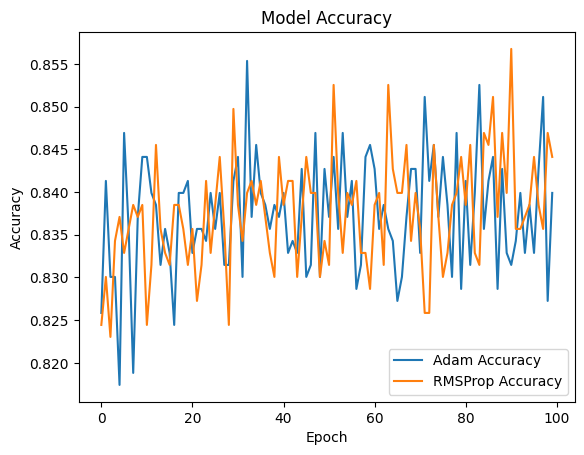

In [ ]:
# plot model for accuracy and loss
plt.plot(adam_history.history['accuracy'], label='Adam Accuracy')
plt.plot(rmsprop_history.history['accuracy'], label='RMSProp Accuracy')

plt.title('Model Accuracy')
plt.xlabel('Epoch')
plt.ylabel('Accuracy')
plt.legend()
plt.show()


# **6. Evaluate the models.**

In [ ]:
# evaluate the models
adam_loss, adam_accuracy = adam_model.evaluate(X_test, y_test)
rmsp_loss, rmsp_accuracy = rmsprop_model.evaluate(X_test, y_test)

6/6 ━━━━━━━━━━━━━━━━━━━━ 0s 11ms/step - accuracy: 0.8286 - loss: 0.4378 
6/6 ━━━━━━━━━━━━━━━━━━━━ 0s 11ms/step - accuracy: 0.8112 - loss: 0.4323 


In [ ]:
print(f"Adam - Loss: {adam_loss:.4f}, Accuracy: {adam_accuracy:.4f}")
print(f"RMSprop - Loss: {rmsp_loss:.4f}, Accuracy: {rmsp_accuracy:.4f}")

Adam - Loss: 0.4501, Accuracy: 0.8156
RMSprop - Loss: 0.4504, Accuracy: 0.8101


# Reflect

Interpret the model output, and state your conclusions on model performance using Adam, RMSProp, L2 regularisation, and dropout.

What makes this experiment a valid comparison of the two regularisation approaches? Explain why the observed effects can be attributed to the regularisation techniques. If you perform the experiment repeatedly, what kind of variation would you expect in your results?

Write a brief paragraph highlighting your process and the rationale to showcase critical thinking and problem-solving.

Adam Loss was 0.4392 and accuracy of 82.68%
RMSprop Loss was 0.4399 and accuracy of 81.56%

Both are very close, but Adam performs slightly better on both metrics. Still I'd choose Adam as it gets better results for loss and accuracy. By adding L2 and Dropout improved the model in comparison to the previous activity. The small difference between the optmizer can be due to the missing values as well. Besides the dataset is pretty small for the optimizers. Furthermore, they helped to prevent overfitting.

# Activity 4.3.3 Implementing early stopping

## Objective
Building on the neural network model, add early stopping callbacks on models trained with Adam and RMSProp.

## Assessment criteria
By completing this activity, you will be able to provide evidence that you can:
- define a function to create and train a neural network model
- interpret model output and explain your conclusions
- select the appropriate model and justify your choice.

## Activity steps
1. Import early stopping from Keras.
3. Add early stopping to a model trained with Adam optimisation that includes the following parameters:
- patience = 1
- lr=0.001
- L2 regularisation of 0.01.
3. Add early stopping to a model trained with RMSProp optimisation that includes the same parameters.
4. Plot model accuracy and loss.
5. Evaluate the models.

# **1. Import early stopping from Keras.**

In [ ]:
# Import early stopping
from keras.callbacks import EarlyStopping
from keras.regularizers import l2

# **2. Add early stopping to a model trained with Adam optimisation that includes the following parameters:**

- patience = 1
- lr=0.001
- L2 regularisation of 0.01.

In [ ]:
# Neural layers
def build_model(optimizer):
  model = tf.keras.Sequential([tf.keras.layers.Dense(32, activation='relu', input_shape=(X_train.shape[1],), kernel_regularizer=l2(0.001)),
                               Dropout(0.3),
                             tf.keras.layers.Dense(16, activation='relu', kernel_regularizer=l2(0.001)),
                               Dropout(0.3),
                             tf.keras.layers.Dense(1, activation='sigmoid')])
  model.compile(optimizer=optimizer, loss='binary_crossentropy', metrics=['accuracy'])

  return model

# Early stopping
early_stopping = tf.keras.callbacks.EarlyStopping(
      monitor="val_loss", patience=1, verbose=0, mode="auto", baseline=None, restore_best_weights=False)

# Pass it to the model
adam_model = build_model(Adam(learning_rate=0.001))
adam_history = adam_model.fit(X_train, y_train, callbacks=[early_stopping], epochs=100, batch_size=32, validation_split=0.2)



Epoch 1/100


/usr/local/lib/python3.12/dist-packages/keras/src/layers/core/dense.py:93: UserWarning: Do not pass an `input_shape`/`input_dim` argument to a layer. When using Sequential models, prefer using an `Input(shape)` object as the first layer in the model instead.
  super().__init__(activity_regularizer=activity_regularizer, **kwargs)


18/18 ━━━━━━━━━━━━━━━━━━━━ 2s 19ms/step - accuracy: 0.5161 - loss: 0.7516 - val_accuracy: 0.8112 - val_loss: 0.6493
Epoch 2/100
18/18 ━━━━━━━━━━━━━━━━━━━━ 0s 7ms/step - accuracy: 0.6142 - loss: 0.6966 - val_accuracy: 0.8252 - val_loss: 0.6090
Epoch 3/100
18/18 ━━━━━━━━━━━━━━━━━━━━ 0s 7ms/step - accuracy: 0.6896 - loss: 0.6477 - val_accuracy: 0.8322 - val_loss: 0.5800
Epoch 4/100
18/18 ━━━━━━━━━━━━━━━━━━━━ 0s 7ms/step - accuracy: 0.7381 - loss: 0.6178 - val_accuracy: 0.8322 - val_loss: 0.5546
Epoch 5/100
18/18 ━━━━━━━━━━━━━━━━━━━━ 0s 7ms/step - accuracy: 0.7225 - loss: 0.6082 - val_accuracy: 0.8252 - val_loss: 0.5321
Epoch 6/100
18/18 ━━━━━━━━━━━━━━━━━━━━ 0s 7ms/step - accuracy: 0.7339 - loss: 0.6258 - val_accuracy: 0.8322 - val_loss: 0.5142
Epoch 7/100
18/18 ━━━━━━━━━━━━━━━━━━━━ 0s 7ms/step - accuracy: 0.7688 - loss: 0.5578 - val_accuracy: 0.8252 - val_loss: 0.4990
Epoch 8/100
18/18 ━━━━━━━━━━━━━━━━━━━━ 0s 7ms/step - accuracy: 0.7606 - loss: 0.5351 - val_accuracy: 0.8182 - val_loss: 0.

# **3. Add early stopping to a model trained with RMSProp optimisation that includes the same parameters.**

In [ ]:
# Train model with RMSProp optimisation abd L2 regularisation
rmsprop_model = build_model(RMSprop(learning_rate=0.001))

# Early stopping
early_stopping = tf.keras.callbacks.EarlyStopping(
      monitor="val_loss", patience=1, verbose=0, mode="auto", baseline=None, restore_best_weights=False)

# Pass it to the model
rmsprop_history = rmsprop_model.fit(X_train, y_train, epochs=100, batch_size=32, callbacks=[early_stopping], validation_split=0.2)

Epoch 1/100


/usr/local/lib/python3.12/dist-packages/keras/src/layers/core/dense.py:93: UserWarning: Do not pass an `input_shape`/`input_dim` argument to a layer. When using Sequential models, prefer using an `Input(shape)` object as the first layer in the model instead.
  super().__init__(activity_regularizer=activity_regularizer, **kwargs)


18/18 ━━━━━━━━━━━━━━━━━━━━ 2s 56ms/step - accuracy: 0.5297 - loss: 0.7302 - val_accuracy: 0.7273 - val_loss: 0.6310
Epoch 2/100
18/18 ━━━━━━━━━━━━━━━━━━━━ 0s 10ms/step - accuracy: 0.6561 - loss: 0.6807 - val_accuracy: 0.7762 - val_loss: 0.5826
Epoch 3/100
18/18 ━━━━━━━━━━━━━━━━━━━━ 0s 8ms/step - accuracy: 0.7046 - loss: 0.6222 - val_accuracy: 0.7972 - val_loss: 0.5520
Epoch 4/100
18/18 ━━━━━━━━━━━━━━━━━━━━ 0s 7ms/step - accuracy: 0.7453 - loss: 0.6191 - val_accuracy: 0.8112 - val_loss: 0.5303
Epoch 5/100
18/18 ━━━━━━━━━━━━━━━━━━━━ 0s 8ms/step - accuracy: 0.7330 - loss: 0.6063 - val_accuracy: 0.8252 - val_loss: 0.5118
Epoch 6/100
18/18 ━━━━━━━━━━━━━━━━━━━━ 0s 7ms/step - accuracy: 0.7973 - loss: 0.5492 - val_accuracy: 0.8322 - val_loss: 0.4939
Epoch 7/100
18/18 ━━━━━━━━━━━━━━━━━━━━ 0s 7ms/step - accuracy: 0.7914 - loss: 0.5469 - val_accuracy: 0.8252 - val_loss: 0.4810
Epoch 8/100
18/18 ━━━━━━━━━━━━━━━━━━━━ 0s 7ms/step - accuracy: 0.7671 - loss: 0.5566 - val_accuracy: 0.8182 - val_loss: 0

# **4. Plot model accuracy and loss.**

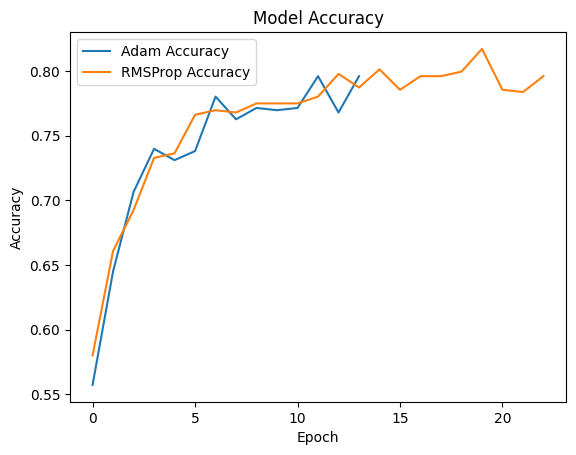

In [ ]:
# Plot model accuracy
plt.plot(adam_history.history['accuracy'], label='Adam Accuracy')
plt.plot(rmsprop_history.history['accuracy'], label='RMSProp Accuracy')

plt.title('Model Accuracy')
plt.xlabel('Epoch')
plt.ylabel('Accuracy')
plt.legend()
plt.show()

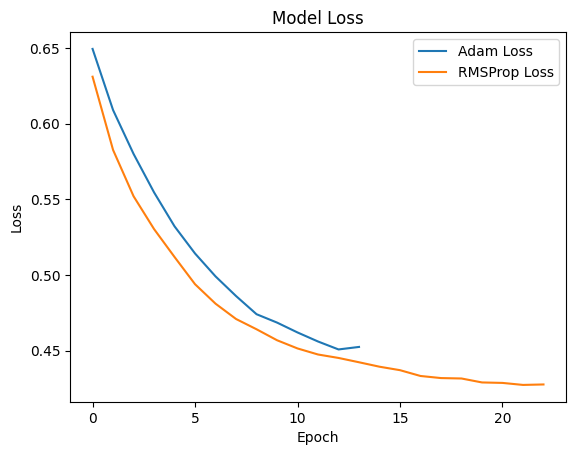

In [ ]:
# Plot model loss
plt.plot(adam_history.history['val_loss'], label='Adam Loss')
plt.plot(rmsprop_history.history['val_loss'], label='RMSProp Loss')

plt.title('Model Loss')
plt.xlabel('Epoch')
plt.ylabel('Loss')
plt.legend()
plt.show()

# **5. Evaluate the models.**

In [ ]:
# evaluate the models
adam_loss, adam_accuracy = adam_model.evaluate(X_test, y_test)
rmsp_loss, rmsp_accuracy = rmsprop_model.evaluate(X_test, y_test)

6/6 ━━━━━━━━━━━━━━━━━━━━ 0s 7ms/step - accuracy: 0.8255 - loss: 0.4585 
6/6 ━━━━━━━━━━━━━━━━━━━━ 0s 7ms/step - accuracy: 0.8117 - loss: 0.4317 


# Reflect

Interpret the model output, and state your conclusions on model performance using Adam, RMSProp,and early stopping callbacks.

Explain why the observed effects can be attributed to the early stopping callback. If you perform the experiment repeatedly, what kind of variation would you expect in your results?

Write a brief paragraph highlighting your process and the rationale to showcase critical thinking and problem-solving.

The neural network built and progressively improved by predicting the likelyhood of Titanic survivors.
When compared the 3 of them, the basic model, Adam and RMSprop achivived over 80% accuracy including the second activity which included the L2 regularization and the dropout.

When we put on numbers they were:


- Activity 1:
  Adam: 81.56% accuracy, loss: 0.4598
  RMSprop: 81.01% accuracy, loss: 0.4473
- Activity 2:
  Adam: 82.68% accuracy, loss: 0.4392
  RMSprop: 81.56% accuracy, loss: 0.4399
- Activity 3:
  Adam: 82.55% accuracy, loss: 0.4585
  RMSprop: 81.17% accuracy, loss: 0.4317

We can see the Adam lost the accuracy in actitivity 3 as we used an early stop and the loss increased. However RMSprop the acuracy decrease slightly but the loss decrease.

Therefore, if we think about the problem involve human lives the most apropriete model would be the second using Adam as there are a higher accuracy is the highest one and this overcome any computational costs etc.
